# PCN MNIST Probe

This notebook checks whether the real-valued PCN can learn an image-label task. It defaults to scikit-learn's bundled digits dataset so it runs offline. Set `USE_FULL_MNIST = True` to fetch OpenML MNIST when network access or a local cache is available.

In [9]:
from pathlib import Path
import sys

from tqdm import tqdm

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))


In [ ]:
from qvnn_pc.models import PredictiveCodingNetwork

EPOCHS = 100
BATCH_SIZE = 512
ETA_INFER = 0.05
ETA_LEARN = 0.005
T_INFER_TRAIN = 50 
T_INFER_EVAL = 50
T_LEARN = 128
SEED = 7


device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float32
torch.manual_seed(SEED)
np.random.seed(SEED)
device

'cuda'

In [34]:
mnist_train_data = MNIST(root="data", train=True, download=True, transform=ToTensor())
mnist_test_data = MNIST(root="data", train=False, download=True, transform=ToTensor())

In [35]:
# 1. Daten laden und direkt abflachen (für Linear Layers)
# Wenn Sie CNNs nutzen, lassen Sie das .reshape(-1, 784) weg!
x_all = mnist_train_data.data.float().reshape(-1, 784) / 255.0
y_all_labels = mnist_train_data.targets
y_all = F.one_hot(y_all_labels, num_classes=10).float()

# 2. Präziser Split mittels Slicing
x_val, x_train = x_all[-10000:], x_all[:-10000]
y_val, y_train = y_all[-10000:], y_all[:-10000]
y_val_labels, y_train_labels = y_all_labels[-10000:], y_all_labels[:-10000]

# 3. Testdaten verarbeiten
x_test = mnist_test_data.data.float().reshape(-1, 784) / 255.0
y_test_labels = mnist_test_data.targets
y_test = F.one_hot(y_test_labels, num_classes=10).float()


In [36]:
# 1. Standardisierung direkt in PyTorch (kein Wechsel zu NumPy nötig)
# axis=0 entspricht dim=0 in PyTorch
x_mean = x_train.mean(dim=0, keepdim=True)
x_std = x_train.std(dim=0, keepdim=True).clamp(min=1e-6)

# 2. Daten transformieren und auf das Zielgerät/Datentyp übertragen
x_train = ((x_train - x_mean) / x_std).to(dtype=dtype, device=device)
x_val = ((x_val - x_mean) / x_std).to(dtype=dtype, device=device)

# 3. Labels auf das Zielgerät übertragen
y_train_labels = y_train_labels.to(dtype=torch.long, device=device)
y_val_labels = y_val_labels.to(dtype=torch.long, device=device)

# 4. One-Hot-Encoding erstellen
y_train = F.one_hot(y_train_labels, num_classes=10).to(dtype=dtype, device=device)
y_val = F.one_hot(y_val_labels, num_classes=10).to(dtype=dtype, device=device)

# Variable für den Titel des Plots definieren
dataset_name = "MNIST (Standardisiert)"
print(dataset_name, x_train.shape, x_val.shape)

MNIST (Standardisiert) torch.Size([50000, 784]) torch.Size([10000, 784])


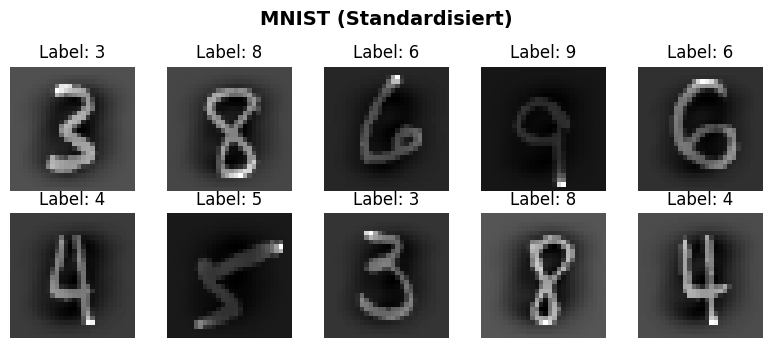

In [37]:

# 1. Daten für die Visualisierung vorbereiten (CPU + NumPy)
# Wir nutzen die ersten 10 validierten Bilder als Stichprobe
x_np = x_val[:10].cpu().numpy()
y_np = y_val_labels[:10].cpu().numpy()
image_shape = (28, 28) # MNIST Standard-Form

# 2. Grid plotten
fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))
for ax, image, label in zip(axes.ravel(), x_np, y_np):
    ax.imshow(image.reshape(image_shape), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

fig.suptitle(dataset_name, fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()


In [38]:
model = PredictiveCodingNetwork(
    [x_train.shape[1], 128, 64, 32],
    output_dim=10,
    activation="tanh",
    optimizer="Adagrad",
    prediction_inference_steps=T_INFER_EVAL,
    prediction_eta_infer=ETA_INFER,
    device=device,
    dtype=dtype,
)


@torch.no_grad()
def classification_metrics(x, labels, targets):
    scores = model.fast_predict(x)
    pred = scores.argmax(dim=1)
    accuracy = (pred == labels).float().mean().item()
    mse = (scores - targets).square().mean().item()
    return accuracy, mse


classification_metrics(x_val, y_val_labels, y_val)

(0.08829999715089798, 0.47383156418800354)

In [39]:
history = {
    "epoch": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "train_mse": [],
    "val_mse": [],
}

generator = torch.Generator(device="cpu").manual_seed(SEED)
for epoch in tqdm(range(1, EPOCHS + 1)):
    permutation = torch.randperm(x_train.shape[0], generator=generator, device="cpu")
    for start in tqdm(range(0, x_train.shape[0], BATCH_SIZE), leave=False):
        batch_idx = permutation[start:start + BATCH_SIZE].to(device)
        model.train_batch(
            x_train[batch_idx],
            y_train[batch_idx],
            eta_infer=ETA_INFER,
            eta_learn=ETA_LEARN,
            T_infer=T_INFER_TRAIN,
            T_learn=T_LEARN,
            latent_init="feedforward",
        )

    train_acc, train_mse = classification_metrics(x_train, y_train_labels, y_train)
    val_acc, val_mse = classification_metrics(x_val, y_val_labels, y_val)
    history["epoch"].append(epoch)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)
    history["train_mse"].append(train_mse)
    history["val_mse"].append(val_mse)

  0%|          | 0/100 [00:00<?, ?it/s]

 11%|█         | 11/100 [05:17<42:49, 28.88s/it]


KeyboardInterrupt: 

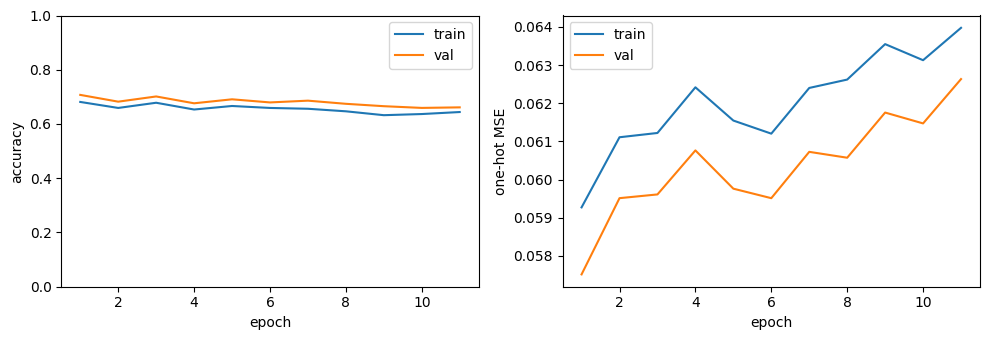

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history["epoch"], history["train_accuracy"], label="train")
axes[0].plot(history["epoch"], history["val_accuracy"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].plot(history["epoch"], history["train_mse"], label="train")
axes[1].plot(history["epoch"], history["val_mse"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("one-hot MSE")
axes[1].legend()
fig.tight_layout()

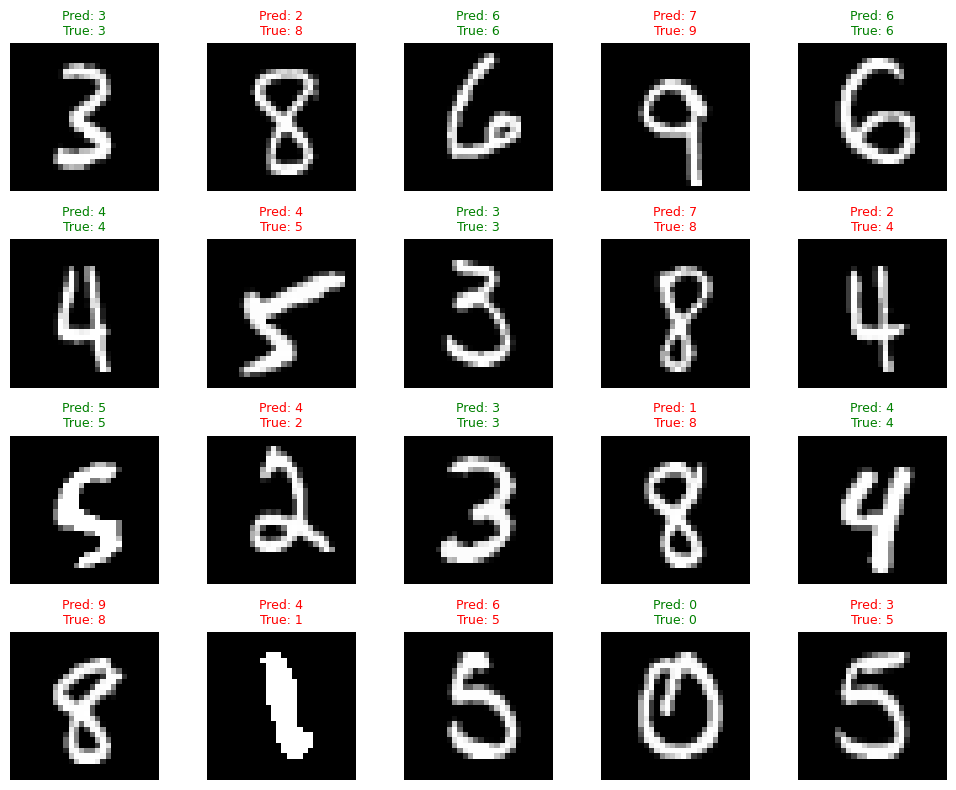

In [45]:
@torch.no_grad()
def show_predictions(count=20):
    # 1. Vorhersagen holen
    scores = model.fast_predict(x_val[:count])
    pred = scores.argmax(dim=1).cpu().numpy()
    true = y_val_labels[:count].cpu().numpy()
    
    # 2. Normalisierungs-Parameter auf CPU holen
    mean_cpu = x_mean.squeeze().cpu().numpy()
    std_cpu = x_std.squeeze().cpu().numpy()
    
    # 3. Grid berechnen
    cols = 5
    rows = int(np.ceil(count / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.0 * rows))
    axes_flat = axes.ravel()
    
    # 4. Bilder plotten und denormalisieren
    for i in range(count):
        ax = axes_flat[i]
        # Bild zurück auf CPU und in NumPy konvertieren
        img_np = x_val[i].cpu().numpy()
        
        # Denormalisierung für korrekte Darstellung
        restored = img_np * std_cpu + mean_cpu
        
        # Plot konfigurieren
        ax.imshow(restored.reshape(image_shape), cmap="gray")
        color = "green" if pred[i] == true[i] else "red"
        ax.set_title(f"Pred: {pred[i]}\nTrue: {true[i]}", color=color, fontsize=9)
        ax.axis("off")
        
    # 5. Überflüssige leere Subplots ausblenden
    for ax in axes_flat[count:]:
        ax.axis("off")
        
    fig.tight_layout()
    plt.show()

# Funktion aufrufen
show_predictions()

In [46]:
# 1. Testdaten mit den Statistiken des TRAININGSSETS standardisieren
# Wichtig: Nutzen Sie x_mean und x_std aus dem Training, nicht die Test-Statistiken!
x_test_scaled = ((x_test - x_mean) / x_std).to(dtype=dtype, device=device)

# 2. Labels auf das korrekte Gerät und den richtigen Datentyp bringen
y_test_labels = y_test_labels.to(dtype=torch.long, device=device)
y_test = y_test.to(dtype=dtype, device=device)

# 3. Metriken berechnen
test_acc, test_mse = classification_metrics(x_test_scaled, y_test_labels, y_test)

#calc F1-Score
from sklearn.metrics import f1_score
with torch.no_grad():
    scores = model.fast_predict(x_test_scaled)
    pred_labels = scores.argmax(dim=1).cpu().numpy()
    true_labels = y_test_labels.cpu().numpy()
    test_f1 = f1_score(true_labels, pred_labels, average="weighted")


print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test MSE:      {test_mse:.6f}")
print(f"Test F1:       {test_f1:.6f}")


Test Accuracy: 63.22%
Test MSE:      0.063098
Test F1:       0.616411
